# CsI(Tl)–SiPM：Geant4 真值与 α/γ PID

日期：2026-10-29。接续 [波形校准笔记](codex_0001_csi_geant4_waveform_calibration.ipynb)。
本轮使用真实 Geant4 核衰变与光学输运产生的波形，加入共同读出条件检查，完成 PID–Q 图、分箱 FOM、
测试母事件 ROC 与固定阈值检查。**模拟可以用于条件 PID 研究；当前结果尚不代表实验粒子效率或完整探测器响应已验证。**

没有重新调节发光、源距、光产额、SiPM 增益或噪声参数，也没有覆盖上轮结果。
现有 4000 个 Co 与 24000 个 Am 母衰变在三种读出状态中复用；本轮只新增三次原生 C++ 数字化重放，
不增加独立输运样本。前触发状态和信号残差在每个场景内对两种源完全相同。


In [1]:
from pathlib import Path
import json, math, sys
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT = PROJECT/'simulation/results/pid_20261029'
def read(p): return json.loads(Path(p).read_text())
def table(headers, rows):
    return '\n'.join(['|'+'|'.join(headers)+'|', '|'+'|'.join(['---']*len(headers))+'|'] + ['|'+'|'.join(map(str,r))+'|' for r in rows])
protocol=read(OUT/'protocol.json'); result=read(OUT/'pid.json'); cuts=read(OUT/'thresholds.json')
methods=protocol['methods']; labels={'qdc':'长短门积分比','negative_mean_time':'负平均时间','pca_projection':'冻结 PCA'}
print('Project:',PROJECT)
print('Python / NumPy:',sys.version.split()[0],np.__version__)
print('执行方式：本地 IPython 进程内逐代码单元执行；保存标准 ipynb 输出。')

Project: /media/sf_works/SiPM
Python / NumPy: 3.13.5 2.5.4
执行方式：本地 IPython 进程内逐代码单元执行；保存标准 ipynb 输出。


## 1. 真值不能由源名代替

主要定义：在 CsI 内，某个衰变祖先类别贡献至少 **90% 的沉积能量**，则称该类别主导；
保留 α 后代、γ 后代、衰变电子、混合/其他及无沉积类别。α 产生的次级电子仍属于 α 祖先类别。
此外检查 80% / 95% 能量占比和 90% 雪崩电荷占比；雪崩电荷不等同于有限门 ADC 积分。

²⁴¹Am 的 γ 和电子保留在模拟中。下表给出所有母衰变及最终共同 Q 区间的真值数目。
在当前幅度和 Q 门下 Am 合格波形主要来自 α，不等于 Am 是纯 α 源，也不等于所有实测 Am 波形都是 α。


In [2]:
names=['alpha_family','gamma_family','decay_electron_family','mixed_other','no_deposit']
rows=[]
for source in ['Co60','Am241']:
    e=read(OUT/f'extraction/run12_{source}.json')
    for stage in ['all_mothers','selected','common_Q','common_train','common_test']:
        r=e['counts'][stage]
        rows.append([source,stage,r['n'],*[r['truth_counts'][k] for k in names]])
display(Markdown(table(['源','筛选阶段','总数','α后代','γ后代','衰变电子','混合/其他','无沉积'],rows)))

|源|筛选阶段|总数|α后代|γ后代|衰变电子|混合/其他|无沉积|
|---|---|---|---|---|---|---|---|
|Co60|all_mothers|4000|0|411|3|0|3586|
|Co60|selected|340|0|340|0|0|0|
|Co60|common_Q|129|0|129|0|0|0|
|Co60|common_train|67|0|67|0|0|0|
|Co60|common_test|62|0|62|0|0|0|
|Am241|all_mothers|24000|189|188|7|0|23616|
|Am241|selected|189|189|0|0|0|0|
|Am241|common_Q|172|172|0|0|0|0|
|Am241|common_train|80|80|0|0|0|0|
|Am241|common_test|92|92|0|0|0|0|

## 2. 共同读出、固定特征与训练/测试分离

保留三个既有采集读出状态 run3、run12、run18，**每个状态都对 α 与 γ 使用相同的 SiPM、负载、RC、基线噪声和信号残差**。
主场景为 run12；run3/run18 为敏感性场景。原来 Co 使用 run3、Am 使用 run12 的组合仅作诊断对照。
源几何仍是上一阶段的候选配置，未将几何差异当作 PID 输入。

实验使用已冻结波形 ID。模拟重新执行质量/前触发检查、幅度≥200 ADC、t10≥384 样本和完整3 µs窗口检查；
共同 Q 为 201824.1125–418733.2 ADC·sample。硬件触发未仿真，接受率仅以这些合格波形为分母。
采样2 ns；基线取最前128点，anchor=floor(t10)+1：

- 长短门：Q[−40,500 ns) / Q[−40,3000 ns)。
- 负平均时间：在同一长门内以波形幅度加权的平均时间取负，单位 µs。
- PCA：直接使用既有实验前段训练的76个40 ns积分块模型，不在本轮重训。

原始母事件先按固定随机种子分为训练/测试各半，同一母事件在所有读出重放中保持相同分组。
仅用主场景训练 α 的95%经验分位数确定阈值，再对所有状态的测试事件固定使用；低分区为 score≤阈值。
由于有限样本和 `higher` 分位数取法，训练实际保留比例为96.25%，不是精确95%。
模型/PCA之前已用实验前段校准；这些数据和模拟以前已检查过，本轮不能称为新的盲实验验证。


|方法|低分区上界|训练α数|训练保留比例|
|---|---|---|---|
|长短门积分比|0.36172309|80|96.25%|
|负平均时间|-0.94279273|80|96.25%|
|冻结 PCA|-0.46932085|80|96.25%|

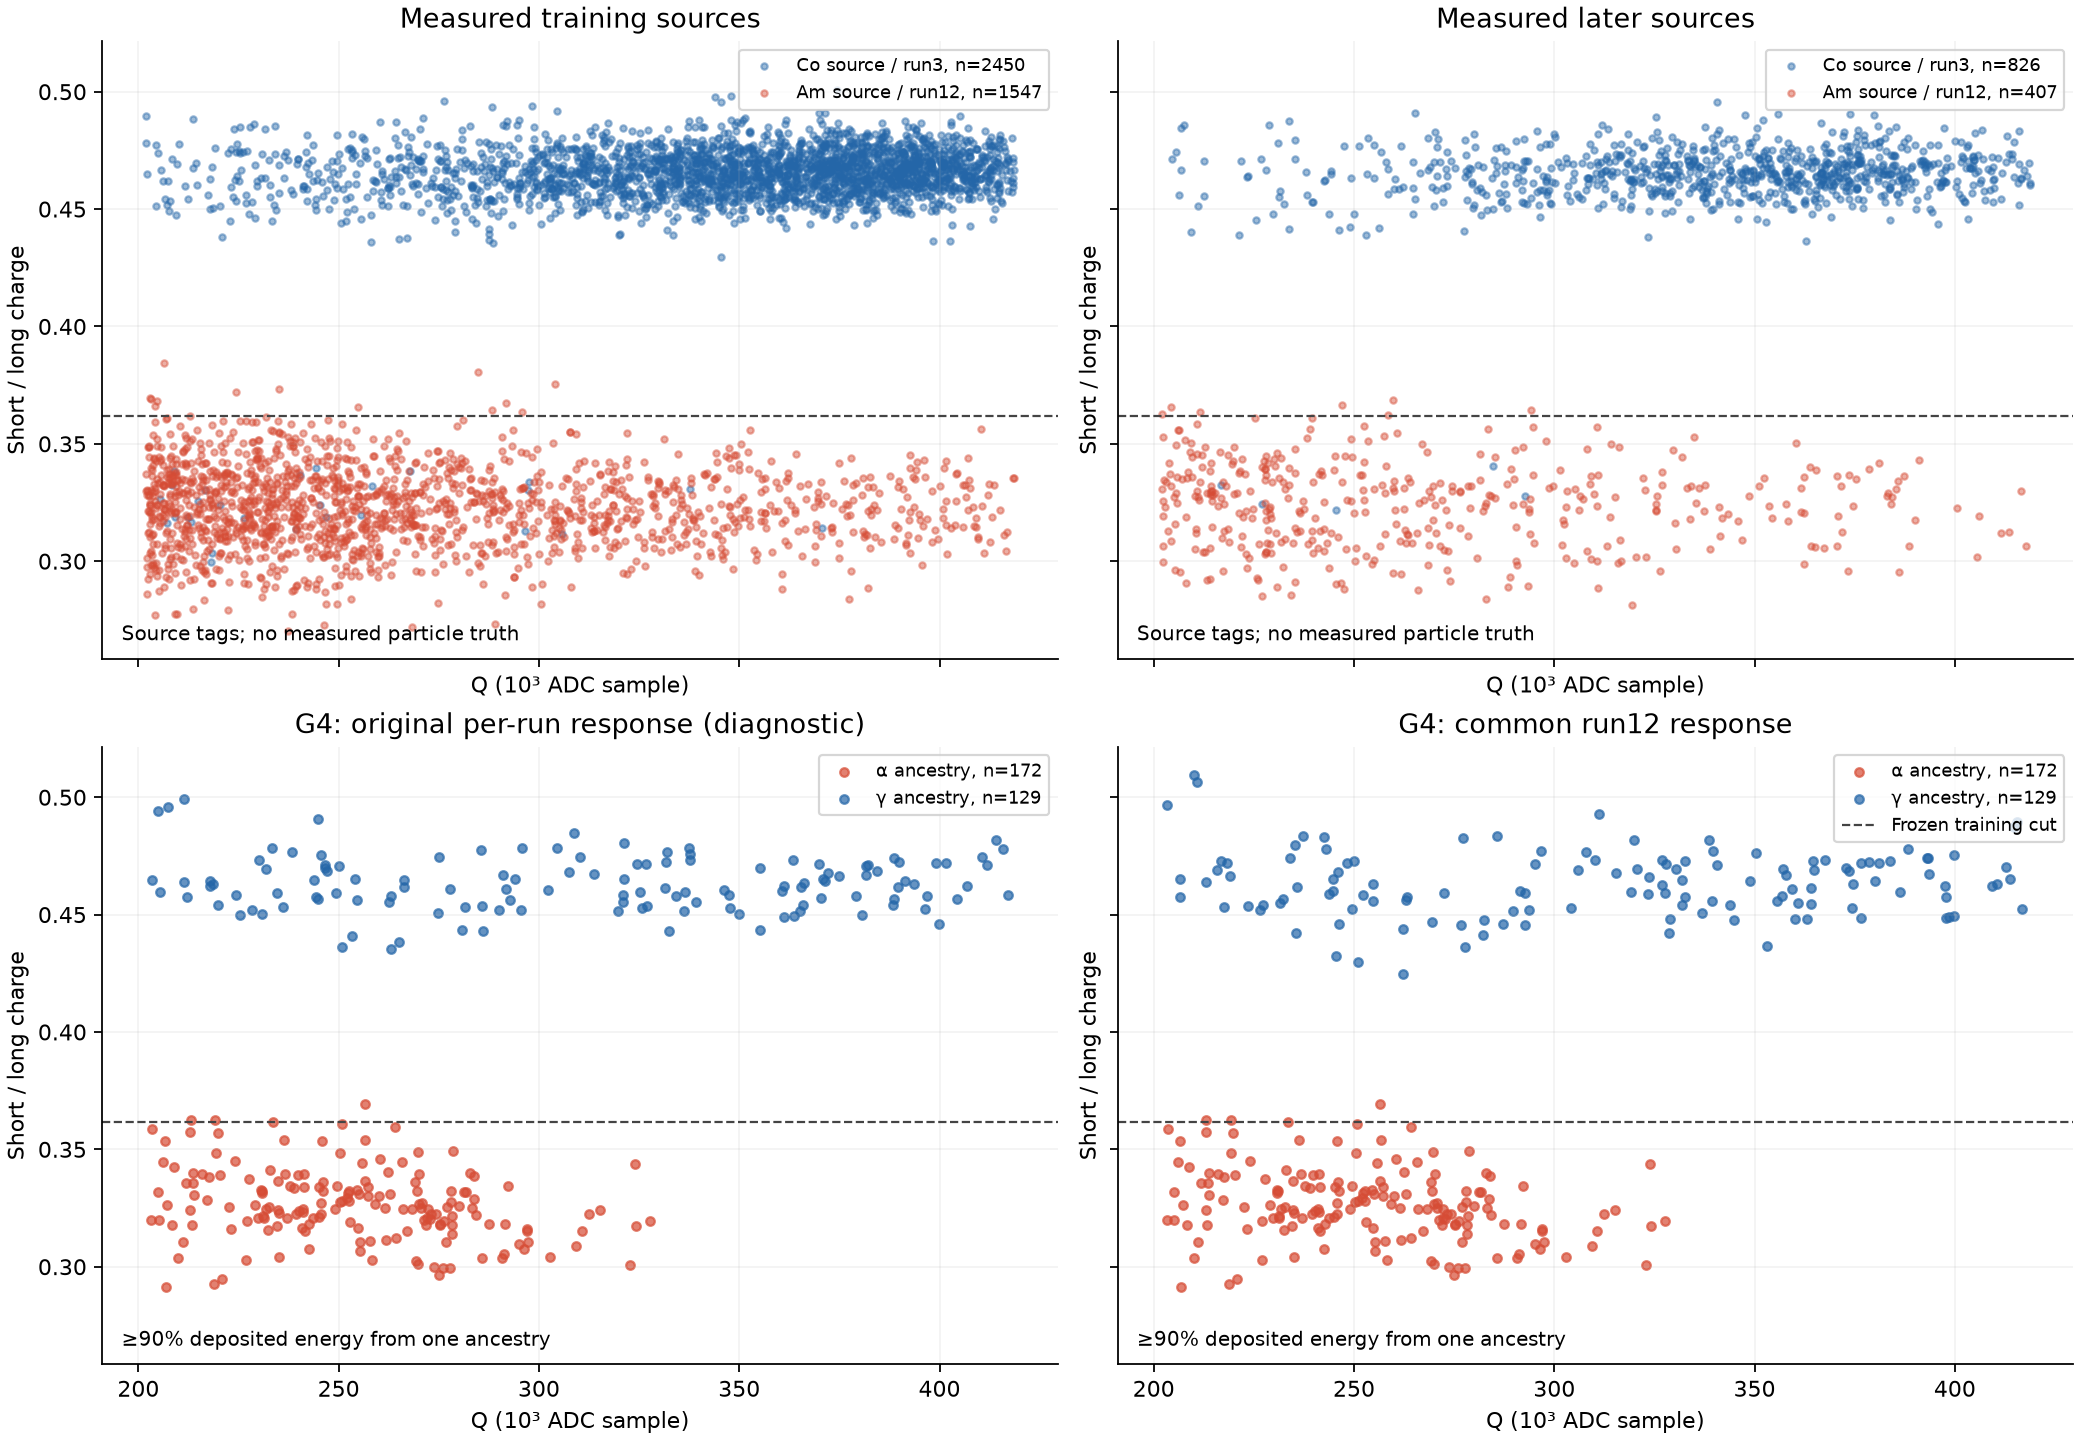

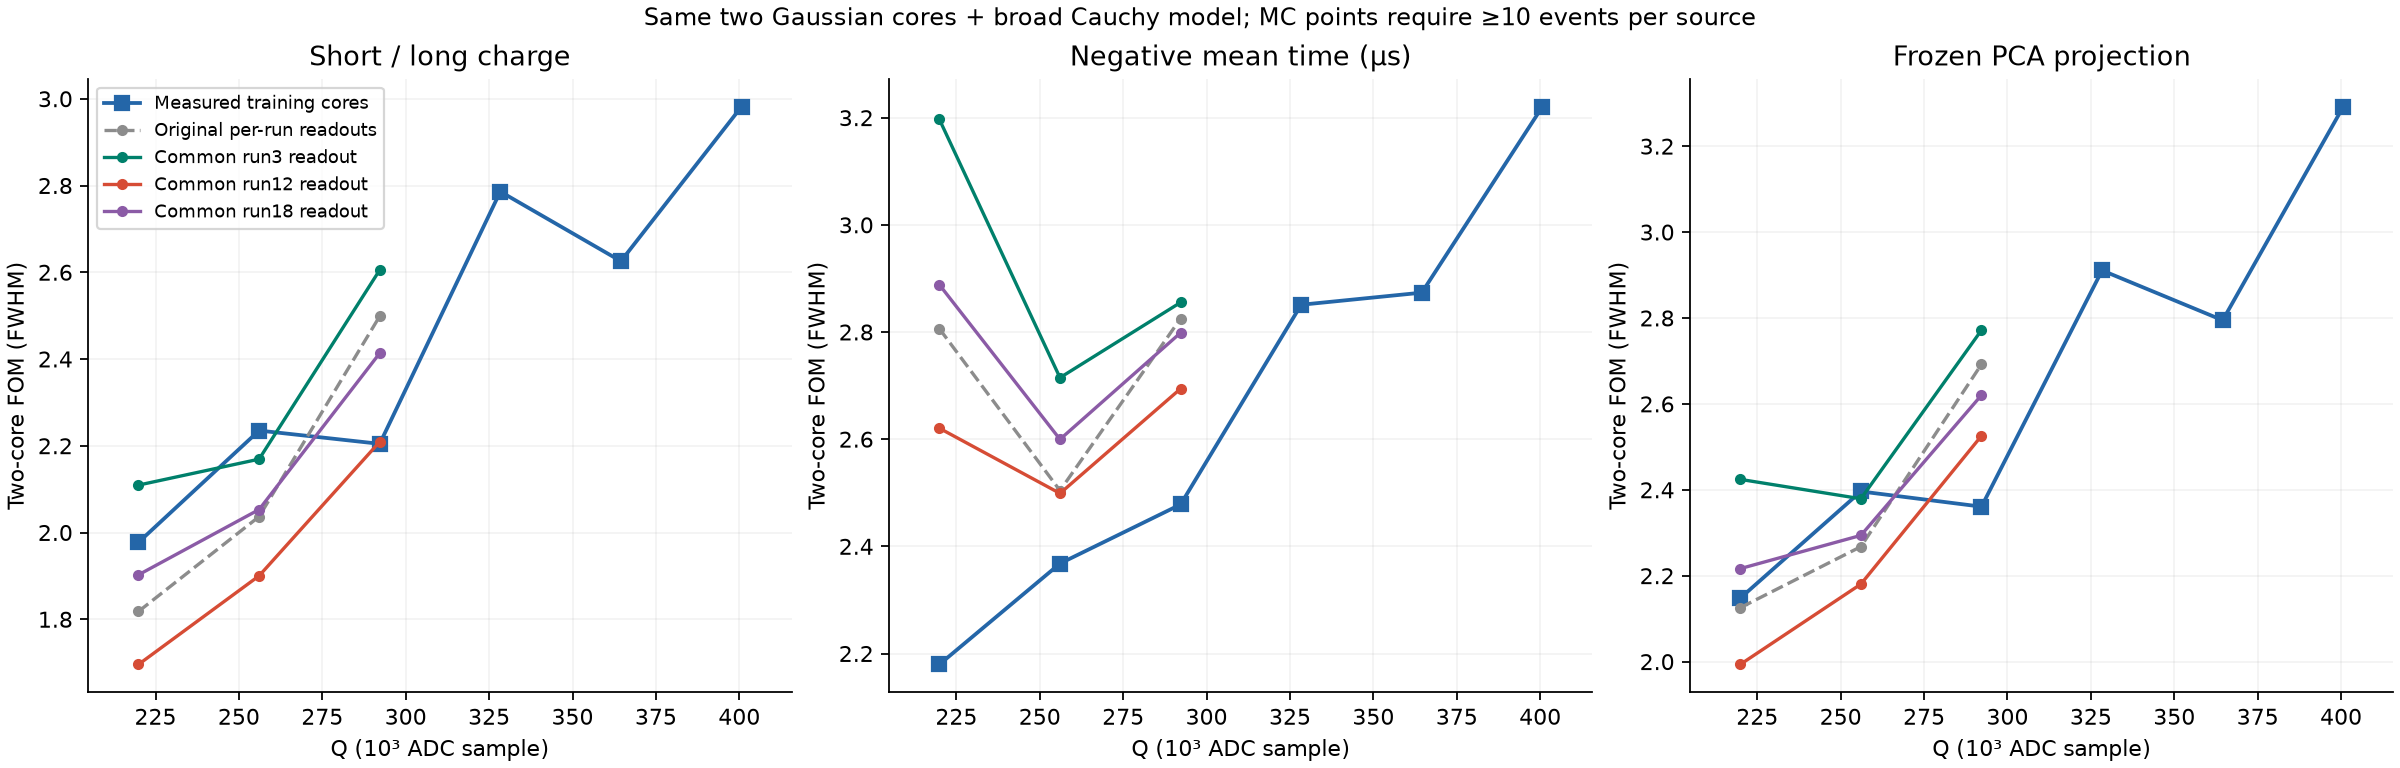

In [3]:
rows=[]
for m in methods:
    c=cuts['methods'][m]
    rows.append([labels[m],f"{c['threshold']:.8f}",c['n_training_alpha'],f"{100*c['training_retained_fraction']:.2f}%"])
display(Markdown(table(['方法','低分区上界','训练α数','训练保留比例'],rows)))
for stem in ['pid_truth_and_measurement','pid_core_fom_vs_charge']:
    display(Image(filename=str(OUT/f'figures/{stem}.png')))

FOM 图对模拟与实验采用相同的“两条 Gaussian 核心＋宽 Cauchy 项”描述，并允许不同源有不同混合比例。
FOM=|μH−μL|/(FWHMH+FWHML)。这些是统计波形带，不把实验核心直接认定为粒子标签。
模拟每个 Q 箱至少要求每源10条，缺失高 Q 点代表样本支持不足，不能补线外推。
另存按模拟真值分组的均值/标准差 Gaussian 等效 FOM，二者不混写；它们也不能代替尾部误判率。


In [4]:
rows=[]
for state in ['run3','run12','run18']:
    for m in methods:
        fits=[f for f in result['cases'][state]['methods'][m]['source_mixture_fits'] if f['valid']]
        rows.append([state,labels[m],', '.join(str(f['bin']+1) for f in fits),', '.join(f"{f['fit']['shape_fom_fwhm']:.3f}" for f in fits)])
display(Markdown(table(['共同读出状态','方法','有支持的Q箱（从1开始）','核心FOM'],rows)))

|共同读出状态|方法|有支持的Q箱（从1开始）|核心FOM|
|---|---|---|---|
|run3|长短门积分比|1, 2, 3|2.109, 2.169, 2.605|
|run3|负平均时间|1, 2, 3|3.197, 2.715, 2.855|
|run3|冻结 PCA|1, 2, 3|2.424, 2.379, 2.772|
|run12|长短门积分比|1, 2, 3|1.696, 1.900, 2.209|
|run12|负平均时间|1, 2, 3|2.620, 2.499, 2.694|
|run12|冻结 PCA|1, 2, 3|1.993, 2.180, 2.526|
|run18|长短门积分比|1, 2, 3|1.902, 2.053, 2.413|
|run18|负平均时间|1, 2, 3|2.888, 2.600, 2.799|
|run18|冻结 PCA|1, 2, 3|2.217, 2.294, 2.620|

## 3. 测试母事件 ROC 与固定工作点

ROC 使用沉积能量真值的 α/γ 主导事件；衰变电子和混合事件不强塞入二分类，数量及其分区另存。
总体 AUC 之外还保存逐 Q 箱 AUC 与各支持箱等权平均，避免只靠不同能谱区分两类。
单个箱的测试 α/γ 各至少5条才能报告 ROC；这种小样本仍不足以精确约束尾部。


零误判时，要把单侧95%上限压到1% / 0.1%以下，至少需独立合格γ测试事件： [299, 2995]


|主场景方法|测试AUC|α保留/总数|α接受率|α双侧95%区间|γ误判/总数|γ单侧95%上限|
|---|---|---|---|---|---|---|
|长短门积分比|1.000|92/92|100.00%|[96.07, 100.00]%|0/62|4.72%|
|负平均时间|1.000|89/92|96.74%|[90.77, 99.32]%|0/62|4.72%|
|冻结 PCA|1.000|90/92|97.83%|[92.37, 99.74]%|0/62|4.72%|

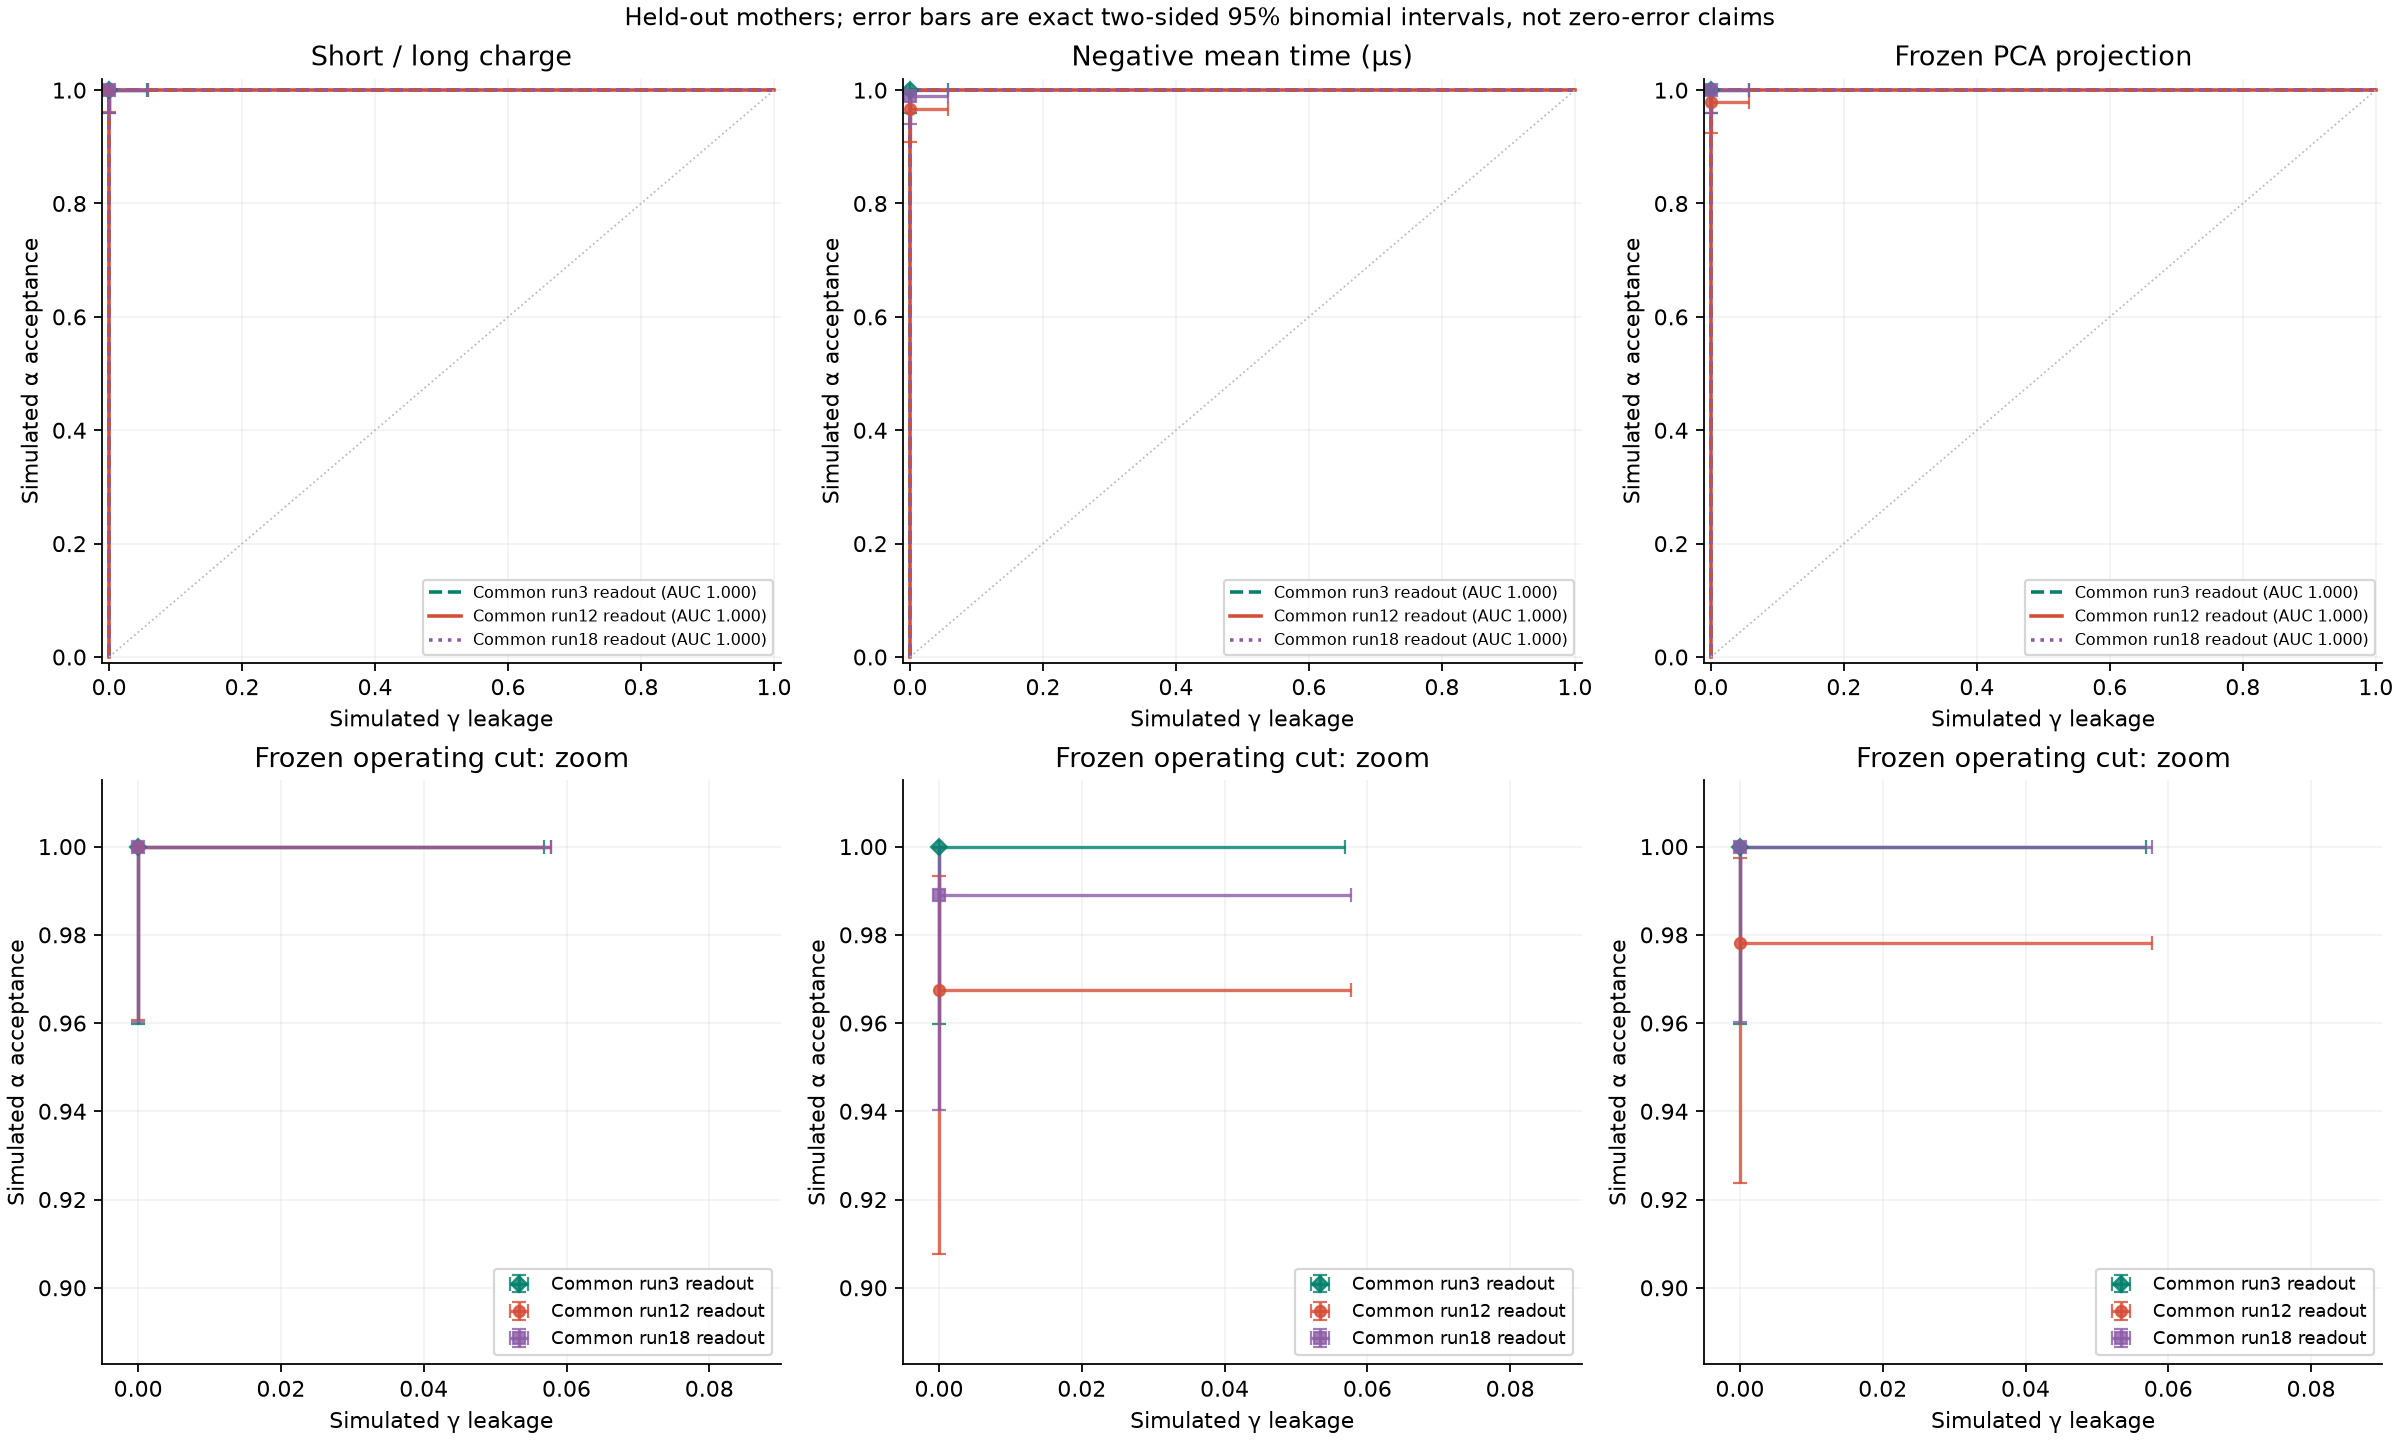

In [5]:
rows=[]
for m in methods:
    r=result['cases']['run12']['methods'][m];a=r['operating']['alpha_acceptance'];g=r['operating']['gamma_leakage']
    rows.append([labels[m],f"{r['test_AUC']:.3f}",f"{a['passed']}/{a['total']}",f"{100*a['fraction']:.2f}%",
      f"[{100*a['exact_two_sided95'][0]:.2f}, {100*a['exact_two_sided95'][1]:.2f}]%",
      f"{g['passed']}/{g['total']}",f"{100*g['one_sided95_upper']:.2f}%"])
display(Markdown(table(['主场景方法','测试AUC','α保留/总数','α接受率','α双侧95%区间','γ误判/总数','γ单侧95%上限'],rows)))
display(Image(filename=str(OUT/'figures/pid_roc_and_operating_points.png')))
print('零误判时，要把单侧95%上限压到1% / 0.1%以下，至少需独立合格γ测试事件：',
      [math.ceil(math.log(.05)/math.log(1-p)) for p in [.01,.001]])

本次主场景有92条 α、62条 γ测试波形。长短门法为92/92 α保留、0/62 γ误判；
负平均时间与PCA分别保留89/92、90/92 α，γ也均为0/62误判。
**零次 γ误判不等于真实泄漏率为零**：单侧95%上限为约4.72%，双侧95%区间上端约5.78%。
三种方法在本批测试中 AUC 均为1；当经验分布没有重叠，普通 bootstrap 的 AUC 区间可能退化为[1,1]，
不能据此证明完美分类或排除未采到的尾部。

512次母事件 bootstrap 对三种状态使用同一组权重，保存成对 FOM/AUC 差异；读出状态不能当作三批独立数据。
区间固定了光学、读出、PCA、选择规则和阈值，未包含这些拟合与未记录装置条件的不确定度。
这些结果也不能用来断言某个算法在实验中一定更优。


## 4. 与实测带宽和低分区的比较

平均波形接近并不保证 PID 带宽和尾部相同。下图在相同 Q 箱中比较 IQR，水平线1表示宽度一致。
IQR 是分布宽度，不是误差条。实验仅按源和 run 分组，没有粒子真值。


实验事件明细： /media/sf_works/SiPM/simulation/results/pid_20261029/measured_pid_regions.csv
模拟真值与预测： /media/sf_works/SiPM/simulation/results/pid_20261029/MC_pid_events.csv


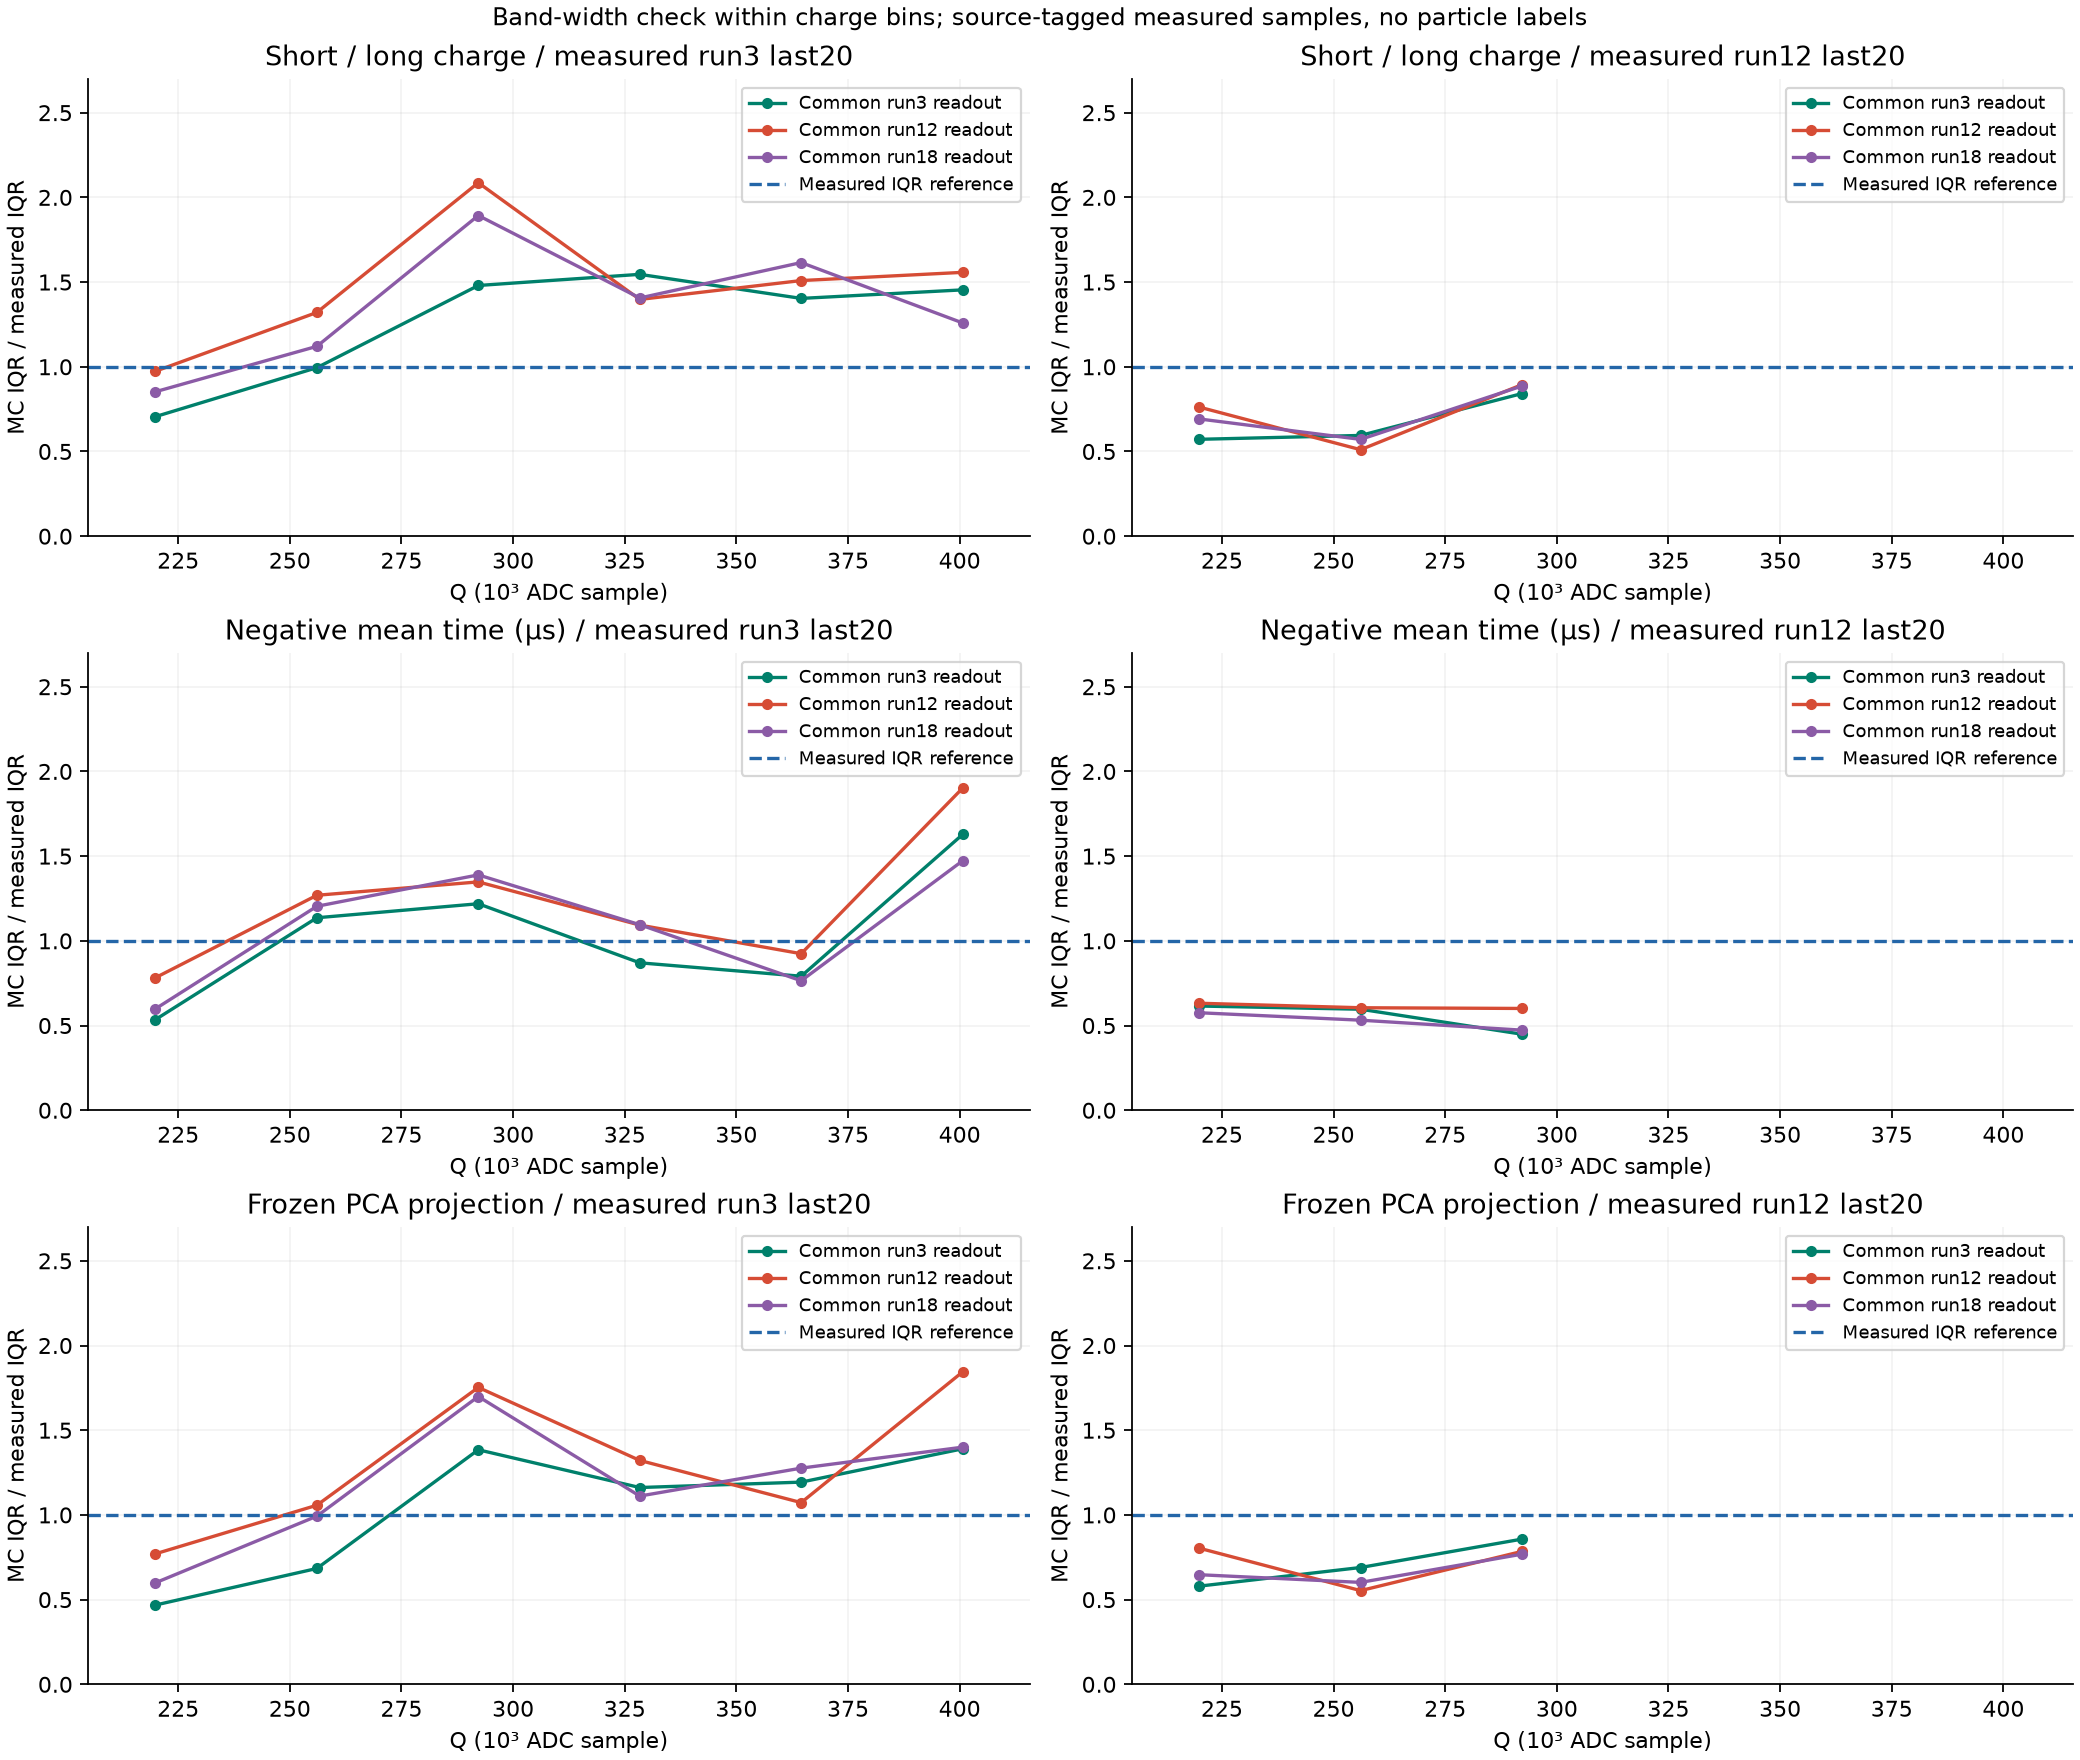

|实测后段run|合格波形数|长短门低分区条数|低分区占比（非粒子效率）|
|---|---|---|---|
|3|826|5|0.605%|
|12|407|400|98.280%|
|18|3000|2990|99.667%|

In [6]:
display(Image(filename=str(OUT/'figures/pid_bandwidth_check.png')))
rows=[]
for run in [3,12,18]:
    r=result['measured'][f'run{run}_last20'];m=r['methods']['qdc']
    rows.append([run,r['n'],round(m['observed_low_score_fraction']*r['n']),f"{100*m['observed_low_score_fraction']:.3f}%"])
display(Markdown(table(['实测后段run','合格波形数','长短门低分区条数','低分区占比（非粒子效率）'],rows)))
print('实验事件明细：',OUT/'measured_pid_regions.csv')
print('模拟真值与预测：',OUT/'MC_pid_events.csv')

实测 run3 后段有5/826条落入长短门低分区，而本批模拟没有采到相应 γ误判尾部。
该0.61%是**Co源测量组的低分区比例**，不能在缺少逐事件真值与背景约束时直接称为 γ泄漏。
run12 后段的若干Q箱中，模拟长短门 IQR 仅约为实测的0.51–0.89；共同 run12 读出下，Co对应箱又可能偏宽。
因此，当前可以展示条件模拟 PID、研究方法与采集状态的影响，但不能宣称已定量复现实验所有 PID 宽度和尾部。

下一阶段的优先事项是：固定读出场景后增加独立 MC 的合格测试事件数；以逐Q箱带宽/尾部作为新的响应验证目标，
检查采集状态、背景及未建模因素。若改动响应，应另开校准/检查批次，保留本次阈值和结果，不能用本批测试反复挑参数。
仍只能使用已有实验数据时，文章应把模拟接受率/泄漏率写成模型条件下的结果。


## 5. 文件与复核

- [冻结分析约定](../simulation/results/pid_20261029/protocol.json)
- [固定阈值及训练母事件](../simulation/results/pid_20261029/thresholds.json)
- [可读取的 PID 配置（含 PCA）](../simulation/results/pid_20261029/pid_classifier.json)
- [完整统计结果](../simulation/results/pid_20261029/pid.json)
- [工作点与区间 CSV](../simulation/results/pid_20261029/operating_points.csv)
- [逐Q箱 PID 表](../simulation/results/pid_20261029/per_Q_PID.csv)
- [实测逐事件分区 CSV](../simulation/results/pid_20261029/measured_pid_regions.csv)
- [模拟逐事件真值及分区 CSV](../simulation/results/pid_20261029/MC_pid_events.csv)
- [验证、源码和输出哈希](../simulation/results/pid_20261029/record.json)

程序依次为 `simulation/prepare_pid.py`、原生 `replay_response`、`extract_pid.py`、`analyze_pid.py`、
`plot_pid.py` 和 `export_pid.py`。它们记录当前固定输出目录，准备与统计步骤拒绝覆盖冻结结果。
笔记生成器 `jupyter/codex_0001_build_pid_notebook.py` 只读取结果并在本地 IPython 中执行展示代码，
重新执行笔记不会重跑输运或调参。关键统计边界的5项测试通过，包括并列分数、ROC面积、零误判上限、
加权重采样与祖先类别。旧波形校准归档保持不变；本轮没有自动提交或推送 GitHub。
